# `(a|b)*abb`: Thompson Construction and Subset Construction
Run the cells top to bottom. Only the standard library is required (Graphviz drawing in the last section is optional).

## 1. Setup and helpers

In [1]:
from collections import defaultdict, deque
import itertools, re

EPS = 'ε'
REGEX = '(a|b)*abb'
ALPHABET = 'ab'


## 2. Step 1: insert explicit concatenation, then Shunting-Yard to postfix
Precedence: `*` (3) > `.` concatenation (2) > `|` (1).

In [5]:
dict(enumerate('(a|b)*abb'))

{0: '(', 1: 'a', 2: '|', 3: 'b', 4: ')', 5: '*', 6: 'a', 7: 'b', 8: 'b'}

In [6]:
PREC = {'*': 3, '.': 2, '|': 1}

def add_concat(r):
    out = []
    for i, c in enumerate(r):
        out.append(c)
        if i + 1 < len(r):
            n = r[i + 1]
            if c not in '(|' and n not in ')|*':
                out.append('.')
    return ''.join(out)

def to_postfix(r, trace=False):
    out, st = [], []
    for c in add_concat(r):
        if c == '(':
            st.append(c)
        elif c == ')':
            while st[-1] != '(':
                out.append(st.pop())
            st.pop()
        elif c in PREC:
            while st and st[-1] != '(' and PREC[st[-1]] >= PREC[c]:
                out.append(st.pop())
            st.append(c)
        else:
            out.append(c)
        if trace:
            print(f"read {c!r:4} output={''.join(out):12} stack={''.join(st)}")
    while st:
        out.append(st.pop())
    return ''.join(out)

print('with explicit concat:', add_concat(REGEX))
postfix = to_postfix(REGEX, trace=True)
print('postfix:', postfix)
assert postfix == 'ab|*a.b.b.'


with explicit concat: (a|b)*.a.b.b
read '('  output=             stack=(
read 'a'  output=a            stack=(
read '|'  output=a            stack=(|
read 'b'  output=ab           stack=(|
read ')'  output=ab|          stack=
read '*'  output=ab|          stack=*
read '.'  output=ab|*         stack=.
read 'a'  output=ab|*a        stack=.
read '.'  output=ab|*a.       stack=.
read 'b'  output=ab|*a.b      stack=.
read '.'  output=ab|*a.b.     stack=.
read 'b'  output=ab|*a.b.b    stack=.
postfix: ab|*a.b.b.


## 3. Step 2: Thompson's construction
Each fragment is a `(start, accept)` pair (one entry, one exit). States are numbered in creation order, so the numbers match the walkthrough.

In [7]:
class NFA:
    def __init__(self, start, accept, trans):
        self.start, self.accept, self.trans = start, accept, trans

    @property
    def n_states(self):
        s = set(self.trans) | {self.accept}
        for d in self.trans.values():
            for t in d.values():
                s |= t
        return len(s)

def thompson(postfix, trace=False):
    trans = defaultdict(lambda: defaultdict(set))
    counter = [0]
    def new():
        counter[0] += 1
        return counter[0] - 1
    def edge(a, sym, b):
        trans[a][sym].add(b)

    stack = []
    for tok in postfix:
        if tok == '.':                       # A . B : one epsilon edge
            b, a = stack.pop(), stack.pop()
            edge(a[1], EPS, b[0])
            frag = (a[0], b[1])
        elif tok == '|':                     # A | B : 2 new states, 4 epsilon edges
            b, a = stack.pop(), stack.pop()
            s, e = new(), new()
            edge(s, EPS, a[0]); edge(s, EPS, b[0])
            edge(a[1], EPS, e); edge(b[1], EPS, e)
            frag = (s, e)
        elif tok == '*':                     # A* : 2 new states, 4 epsilon edges
            a = stack.pop()
            s, e = new(), new()
            edge(s, EPS, a[0]); edge(s, EPS, e)   # enter / bypass
            edge(a[1], EPS, a[0]); edge(a[1], EPS, e)  # loop back / exit
            frag = (s, e)
        else:                                # literal
            s, e = new(), new()
            edge(s, tok, e)
            frag = (s, e)
        stack.append(frag)
        if trace:
            print(f"read {tok!r:4} -> stack: {stack}")
    start, accept = stack.pop()
    return NFA(start, accept, trans)

nfa = thompson(postfix, trace=True)
print()
print('NFA states:', nfa.n_states, '| start =', nfa.start, '| accept =', nfa.accept)


read 'a'  -> stack: [(0, 1)]
read 'b'  -> stack: [(0, 1), (2, 3)]
read '|'  -> stack: [(4, 5)]
read '*'  -> stack: [(6, 7)]
read 'a'  -> stack: [(6, 7), (8, 9)]
read '.'  -> stack: [(6, 9)]
read 'b'  -> stack: [(6, 9), (10, 11)]
read '.'  -> stack: [(6, 11)]
read 'b'  -> stack: [(6, 11), (12, 13)]
read '.'  -> stack: [(6, 13)]

NFA states: 14 | start = 6 | accept = 13


### NFA transition table

In [8]:
def print_nfa(nfa):
    print(f"{'state':>5} | " + ' | '.join(f"{s:^10}" for s in [*ALPHABET, EPS]))
    print('-' * 45)
    states = sorted(set(nfa.trans) | {nfa.accept})
    for q in states:
        tag = ('>' if q == nfa.start else ' ') + ('*' if q == nfa.accept else ' ')
        cells = [str(sorted(nfa.trans[q].get(s, ()))) if nfa.trans[q].get(s) else '-' for s in [*ALPHABET, EPS]]
        print(f"{tag}{q:>3} | " + ' | '.join(f"{c:^10}" for c in cells))

print_nfa(nfa)


state |     a      |     b      |     ε     
---------------------------------------------
    0 |    [1]     |     -      |     -     
    1 |     -      |     -      |    [5]    
    2 |     -      |    [3]     |     -     
    3 |     -      |     -      |    [5]    
    4 |     -      |     -      |   [0, 2]  
    5 |     -      |     -      |   [4, 7]  
>   6 |     -      |     -      |   [4, 7]  
    7 |     -      |     -      |    [8]    
    8 |    [9]     |     -      |     -     
    9 |     -      |     -      |    [10]   
   10 |     -      |    [11]    |     -     
   11 |     -      |     -      |    [12]   
   12 |     -      |    [13]    |     -     
 * 13 |     -      |     -      |     -     


### Sanity check: simulate the NFA directly (set-of-states simulation)

In [9]:
def eps_closure(nfa, states):
    seen, todo = set(states), list(states)
    while todo:
        q = todo.pop()
        for r in nfa.trans[q].get(EPS, ()):
            if r not in seen:
                seen.add(r); todo.append(r)
    return frozenset(seen)

def move(nfa, states, sym):
    return {r for q in states for r in nfa.trans[q].get(sym, ())}

def nfa_accepts(nfa, text, trace=False):
    cur = eps_closure(nfa, {nfa.start})
    if trace: print('start closure:', sorted(cur))
    for ch in text:
        cur = eps_closure(nfa, move(nfa, cur, ch))
        if trace: print(f"after {ch!r}: {sorted(cur)}")
    return nfa.accept in cur

for w in ['abb', 'aabb', 'babb', 'ab', 'abba', '']:
    print(f"{w!r:8} -> {nfa_accepts(nfa, w)}")
nfa_accepts(nfa, 'aabb', trace=True)


'abb'    -> True
'aabb'   -> True
'babb'   -> True
'ab'     -> False
'abba'   -> False
''       -> False
start closure: [0, 2, 4, 6, 7, 8]
after 'a': [0, 1, 2, 4, 5, 7, 8, 9, 10]
after 'a': [0, 1, 2, 4, 5, 7, 8, 9, 10]
after 'b': [0, 2, 3, 4, 5, 7, 8, 11, 12]
after 'b': [0, 2, 3, 4, 5, 7, 8, 13]


True

## 4. Step 3: Subset construction
`δ_DFA(S, a) = ε-closure(Move(S, a))`. New DFA states are named A, B, C, ... in discovery order.

In [10]:
def subset_construction(nfa, alphabet, trace=False):
    start = eps_closure(nfa, {nfa.start})
    names = {start: 'A'}
    dtrans, queue = {}, deque([start])
    if trace:
        print(f"A = eps-closure({nfa.start}) = {sorted(start)}\n")
    while queue:
        S = queue.popleft()
        for a in alphabet:
            mv = move(nfa, S, a)
            T = eps_closure(nfa, mv)
            if not T:
                continue
            if T not in names:
                names[T] = chr(ord('A') + len(names))
                queue.append(T)
            dtrans[(names[S], a)] = names[T]
            if trace:
                print(f"{names[S]} --{a}--> Move={sorted(mv)}  closure={sorted(T)}  = {names[T]}")
    accepting = {names[S] for S in names if nfa.accept in S}
    return names[start], dtrans, accepting, names

start, dtrans, accepting, names = subset_construction(nfa, ALPHABET, trace=True)
print('\nstart:', start, '| accepting:', accepting)


A = eps-closure(6) = [0, 2, 4, 6, 7, 8]

A --a--> Move=[1, 9]  closure=[0, 1, 2, 4, 5, 7, 8, 9, 10]  = B
A --b--> Move=[3]  closure=[0, 2, 3, 4, 5, 7, 8]  = C
B --a--> Move=[1, 9]  closure=[0, 1, 2, 4, 5, 7, 8, 9, 10]  = B
B --b--> Move=[3, 11]  closure=[0, 2, 3, 4, 5, 7, 8, 11, 12]  = D
C --a--> Move=[1, 9]  closure=[0, 1, 2, 4, 5, 7, 8, 9, 10]  = B
C --b--> Move=[3]  closure=[0, 2, 3, 4, 5, 7, 8]  = C
D --a--> Move=[1, 9]  closure=[0, 1, 2, 4, 5, 7, 8, 9, 10]  = B
D --b--> Move=[3, 13]  closure=[0, 2, 3, 4, 5, 7, 8, 13]  = E
E --a--> Move=[1, 9]  closure=[0, 1, 2, 4, 5, 7, 8, 9, 10]  = B
E --b--> Move=[3]  closure=[0, 2, 3, 4, 5, 7, 8]  = C

start: A | accepting: {'E'}


In [11]:
def print_dfa(start, dtrans, accepting, alphabet, states=None):
    states = states or sorted({s for s, _ in dtrans} | set(dtrans.values()))
    print(f"{'state':>6} | " + ' | '.join(f"{a:^5}" for a in alphabet))
    print('-' * (10 + 8 * len(alphabet)))
    for s in states:
        tag = ('>' if s == start else ' ') + ('*' if s in accepting else ' ')
        print(f"{tag}{s:>4} | " + ' | '.join(f"{dtrans.get((s, a), '-'):^5}" for a in alphabet))

print('NFA subset behind each DFA state:')
for S, n in sorted(names.items(), key=lambda kv: kv[1]):
    print(f"  {n} = {sorted(S)}" + ('   <- contains accept state %d' % nfa.accept if nfa.accept in S else ''))
print()
print_dfa(start, dtrans, accepting, ALPHABET)


NFA subset behind each DFA state:
  A = [0, 2, 4, 6, 7, 8]
  B = [0, 1, 2, 4, 5, 7, 8, 9, 10]
  C = [0, 2, 3, 4, 5, 7, 8]
  D = [0, 2, 3, 4, 5, 7, 8, 11, 12]
  E = [0, 2, 3, 4, 5, 7, 8, 13]   <- contains accept state 13

 state |   a   |   b  
--------------------------
>    A |   B   |   C  
     B |   B   |   D  
     C |   B   |   C  
     D |   B   |   E  
 *   E |   B   |   C  


## 5. Step 4: Run the DFA and trace a string

In [12]:
def dfa_accepts(start, dtrans, accepting, text, trace=False):
    s = start
    if trace: print('start', s)
    for ch in text:
        nxt = dtrans.get((s, ch))
        if trace: print(f"  {s} --{ch}--> {nxt}")
        if nxt is None:
            return False
        s = nxt
    return s in accepting

for w in ['aabb', 'babb', 'abba']:
    print(w, '->', dfa_accepts(start, dtrans, accepting, w, trace=True))
    print()


start A
  A --a--> B
  B --a--> B
  B --b--> D
  D --b--> E
aabb -> True

start A
  A --b--> C
  C --a--> B
  B --b--> D
  D --b--> E
babb -> True

start A
  A --a--> B
  B --b--> D
  D --b--> E
  E --a--> B
abba -> False



## 6. Verify against Python's `re` (all binary strings up to length 12)

In [13]:
def check(max_len=12):
    bad = []
    for n in range(max_len + 1):
        for t in itertools.product(ALPHABET, repeat=n):
            w = ''.join(t)
            expected = bool(re.fullmatch(REGEX, w))
            if (nfa_accepts(nfa, w) != expected or
                    dfa_accepts(start, dtrans, accepting, w) != expected):
                bad.append(w)
    return bad

bad = check()
print('mismatches:', bad if bad else 'none, NFA, DFA and re agree on every string')


mismatches: none, NFA, DFA and re agree on every string


## 7. Bonus: minimize the DFA (partition refinement)
Subset construction does not give the smallest DFA. States A and C behave identically, so the minimal DFA has 4 states, not 5.

In [14]:
def minimize(start, dtrans, accepting, alphabet):
    states = sorted({s for s, _ in dtrans} | set(dtrans.values()) | {start})
    part = [set(accepting), set(states) - accepting]
    part = [p for p in part if p]
    changed = True
    while changed:
        changed = False
        def block(s):
            for i, p in enumerate(part):
                if s in p: return i
            return -1
        new = []
        for p in part:
            groups = defaultdict(set)
            for s in p:
                groups[tuple(block(dtrans.get((s, a))) for a in alphabet)].add(s)
            new.extend(groups.values())
            if len(groups) > 1: changed = True
        part = new
    return part

blocks = minimize(start, dtrans, accepting, ALPHABET)
print('equivalence classes:', [sorted(b) for b in blocks])


equivalence classes: [['E'], ['D'], ['A', 'C'], ['B']]


## 8. Optional: draw the graphs with Graphviz
Needs `pip install graphviz` and the Graphviz binary. Skip this cell if unavailable.

In [17]:
!pip install graphviz

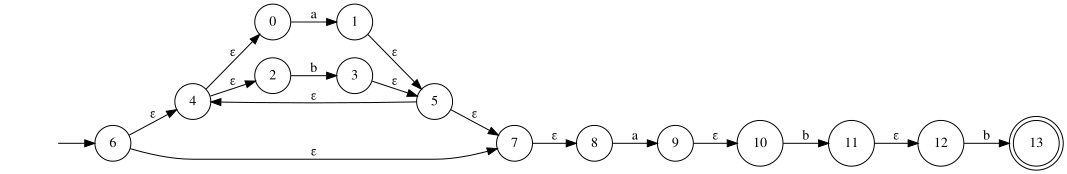

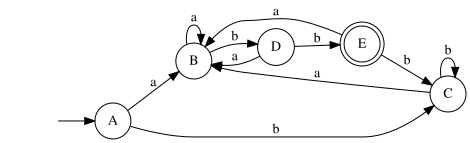

In [18]:
try:
    from graphviz import Digraph

    def draw_nfa(nfa):
        g = Digraph(graph_attr={'rankdir': 'LR'})
        g.node('', shape='none')
        states = sorted(set(nfa.trans) | {nfa.accept})
        for q in states:
            g.node(str(q), shape='doublecircle' if q == nfa.accept else 'circle')
        g.edge('', str(nfa.start))
        for q, d in nfa.trans.items():
            for sym, ts in d.items():
                for t in ts:
                    g.edge(str(q), str(t), label=sym)
        return g

    def draw_dfa(start, dtrans, accepting):
        g = Digraph(graph_attr={'rankdir': 'LR'})
        g.node('', shape='none')
        for s in sorted({s for s, _ in dtrans} | set(dtrans.values())):
            g.node(s, shape='doublecircle' if s in accepting else 'circle')
        g.edge('', start)
        for (s, a), t in dtrans.items():
            g.edge(s, t, label=a)
        return g

    display(draw_nfa(nfa))
    display(draw_dfa(start, dtrans, accepting))
except Exception as e:
    print('Graphviz not available, skipping drawings:', e)


## 9. Try your own regex
The helpers above work for any regex using `|`, `*`, `.`-by-adjacency, `(` `)` and literal characters.

In [19]:
def pipeline(regex, alphabet):
    pf = to_postfix(regex)
    n = thompson(pf)
    s, dt, acc, nm = subset_construction(n, alphabet)
    return pf, n, s, dt, acc, nm

pf, n2, s2, dt2, acc2, nm2 = pipeline('(a|b)*abb', 'ab')
print(pf, '| NFA states:', n2.n_states, '| DFA states:', len(nm2))


ab|*a.b.b. | NFA states: 14 | DFA states: 5
